# Pemodelan & Perbandingan SARIMA vs XGBoost — Harga Mingguan Bawang Merah di Kota Surabaya

Lanjutan dari uji stasioneritas. Data harga harian diagregasi menjadi **mingguan** (rata-rata per minggu, 193 pengamatan). Uji ADF/KPSS menunjukkan data belum stasioner pada data asli dan stasioner setelah *differencing* orde 1, sehingga **d = 1** dipakai pada SARIMA, dengan musiman tahunan **m = 52**.

Tahapan:
1. Pembagian data latih dan data uji (kronologis)
2. **Baseline Naif Musiman** sebagai tolok ukur
3. Pemodelan **SARIMA** (pemilihan orde berdasarkan AIC)
4. Pemodelan **XGBoost** (fitur lag mingguan + kalender, prediksi rekursif)
5. Evaluasi akurasi (MAE, RMSE, MASE) dan perbandingan ketiganya

In [ ]:
import sys

!{sys.executable} -m pip install xgboost scikit-learn statsmodels

In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

KOMODITAS = "Bawang Merah (Kualitas Lokal)"

# jumlah minggu terakhir yang dijadikan data uji
HORIZON = 12

# periode musiman untuk data mingguan (52 = pola tahunan)
MUSIM = 52

## 1. Memuat Data dan Membentuk Deret Waktu Mingguan

Data harga harian dimuat dari CSV, difilter untuk Bawang Merah, lalu diagregasi menjadi rata-rata mingguan.

In [ ]:
df = pd.read_csv(
    "C:/Users/USER/Documents/SEMESTER 5/SARIMA_XGBoost Bawang Merah/harga_komoditas.csv ",
    encoding="utf-8-sig",
    parse_dates=["tanggal"]
)


def ambil_series(nama):
    s = (
        df[df["komoditas"] == nama]
        .set_index("tanggal")["harga"]
        .sort_index()
    )

    # data harian -> diratakan menjadi mingguan
    return s.asfreq("D").interpolate().resample("W").mean()


s = ambil_series(KOMODITAS)

print(f"Komoditas    : {KOMODITAS}")
print(f"Jumlah data  : {len(s)} minggu")
print(f"Periode      : {s.index.min().date()} s.d. {s.index.max().date()}")
s.tail()

Komoditas    : Bawang Merah (Kualitas Lokal)
Jumlah data  : 193 minggu
Periode      : 2023-01-01 s.d. 2026-09-06


tanggal
2026-08-09    31551.020408
2026-08-16    30857.142857
2026-08-23    28734.693878
2026-08-30    29061.224490
2026-09-06    30000.000000
Freq: W-SUN, Name: harga, dtype: float64

## 2. Pembagian Data Latih dan Data Uji

Data dibagi secara kronologis. Data latih digunakan untuk membangun model, sedangkan **12 minggu terakhir** menjadi data uji untuk mengukur akurasi peramalan. Target, periode uji, dan horizon ini dipakai sama untuk ketiga model agar perbandingannya adil.

Data latih : 181 minggu (2023-01-01 s.d. 2026-06-14)
Data uji   : 12 minggu (2026-06-21 s.d. 2026-09-06)


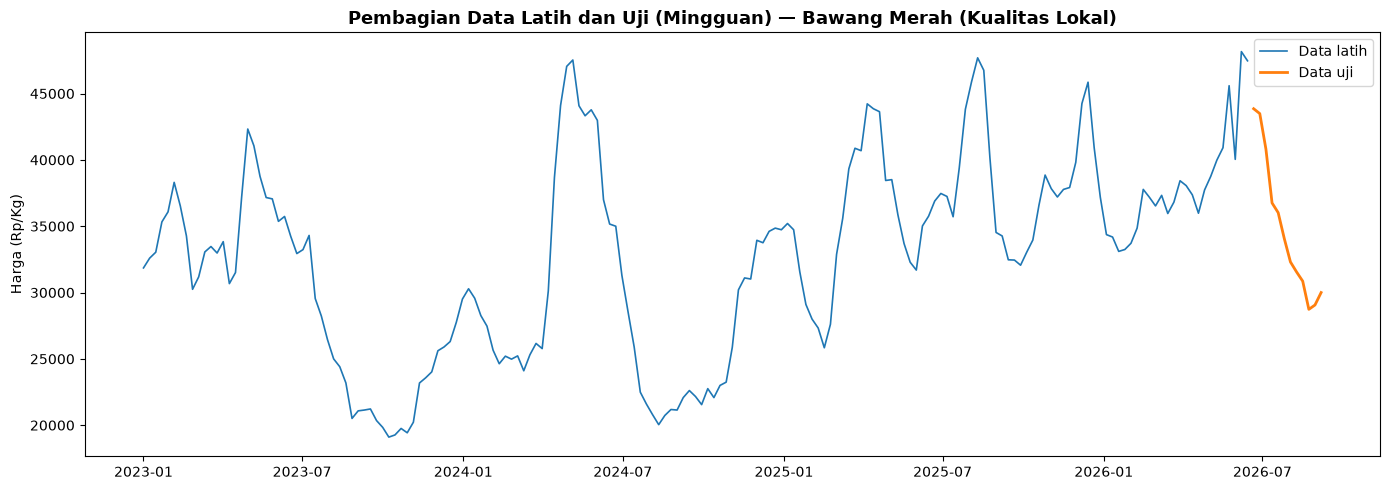

In [4]:
train = s.iloc[:-HORIZON]
test = s.iloc[-HORIZON:]

print(f"Data latih : {len(train)} minggu "
      f"({train.index.min().date()} s.d. {train.index.max().date()})")
print(f"Data uji   : {len(test)} minggu "
      f"({test.index.min().date()} s.d. {test.index.max().date()})")

plt.figure(figsize=(14, 5))
plt.plot(train, color="tab:blue", lw=1.2, label="Data latih")
plt.plot(test, color="tab:orange", lw=2, label="Data uji")
plt.title(f"Pembagian Data Latih dan Uji (Mingguan) — {KOMODITAS}",
          fontsize=13, fontweight="bold")
plt.ylabel("Harga (Rp/Kg)")
plt.legend()
plt.tight_layout()
plt.savefig("pembagian_train_test.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Baseline: Naif Musiman (Seasonal Naive)

Sebagai tolok ukur sederhana, metode **naif musiman** meramalkan harga suatu minggu sama dengan harga pada minggu yang sama **satu tahun sebelumnya** (52 minggu lalu). Baseline ini penting: sebuah model baru dianggap benar-benar bermanfaat apabila mampu mengalahkan prediksi naif musiman (ditunjukkan oleh nilai MASE < 1).

In [5]:
# Naif musiman: nilai 52 minggu sebelumnya
pred_naive = s.shift(MUSIM).reindex(test.index)

## 4. Pemodelan SARIMA

SARIMA ditulis sebagai SARIMA(p, d, q)(P, D, Q)m. Nilai **d = 1** ditetapkan dari uji stasioneritas, dan musiman tahunan ditangani dengan **D = 1** pada **m = 52**. Orde terbaik dipilih dari sekumpulan kandidat berdasarkan **AIC** terkecil.

Catatan: karena musiman m = 52, setiap pemodelan cukup berat. Pencarian dibatasi pada beberapa kandidat orde yang umum agar waktu komputasi wajar (perkiraan beberapa menit).

In [ ]:
KANDIDAT = [
    ((0, 1, 1), (0, 1, 1, MUSIM)),
    ((1, 1, 1), (0, 1, 1, MUSIM)),
    ((2, 1, 2), (0, 1, 1, MUSIM)),
    ((1, 1, 0), (0, 1, 1, MUSIM)),
    ((0, 1, 1), (1, 1, 0, MUSIM)),
    ((1, 1, 1), (1, 1, 1, MUSIM)),
    ((2, 1, 1), (0, 1, 1, MUSIM)),
]


def cari_sarima_terbaik(train, kandidat=KANDIDAT):
    hasil = {"aic": np.inf, "order": None, "seasonal_order": None}

    for order, sorder in kandidat:
        try:
            model = SARIMAX(
                train,
                order=order,
                seasonal_order=sorder,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False, maxiter=50)

            if model.aic < hasil["aic"]:
                hasil = {"aic": model.aic, "order": order, "seasonal_order": sorder}
        except Exception:
            continue

    return hasil


terbaik = cari_sarima_terbaik(train)

print("Orde SARIMA terbaik berdasarkan AIC:")
print(f"  order          = {terbaik['order']}")
print(f"  seasonal_order = {terbaik['seasonal_order']}")
print(f"  AIC            = {terbaik['aic']:.2f}")

Orde SARIMA terbaik berdasarkan AIC:
  order          = (2, 1, 2)
  seasonal_order = (0, 1, 1, 52)
  AIC            = 1383.21


In [7]:
# Melatih SARIMA dengan orde terbaik lalu meramal periode data uji
model_sarima = SARIMAX(
    train,
    order=terbaik["order"],
    seasonal_order=terbaik["seasonal_order"],
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=50)

pred_sarima = model_sarima.get_forecast(steps=len(test)).predicted_mean
pred_sarima.index = test.index

## 5. Pemodelan XGBoost

XGBoost memerlukan data dalam bentuk **supervised learning**, sehingga harga diprediksi dari fitur masa lampau. Karena data mingguan dengan musiman tahunan, fitur **lag 52** (harga pada minggu yang sama tahun lalu) disertakan.

Fitur yang dibentuk:
- **Lag** harga 1, 2, 3, 4, 8, dan **52** minggu sebelumnya
- **Rata-rata** dan **simpangan baku bergerak** 4 minggu
- **Fitur kalender**: minggu ke- (dalam tahun) dan bulan

Peramalan pada data uji dilakukan secara **rekursif**, sehingga XGBoost dan SARIMA sama-sama meramal 12 minggu ke depan tanpa menggunakan nilai aktual data uji.

In [8]:
FITUR = [
    "lag_1", "lag_2", "lag_3", "lag_4", "lag_8", "lag_52",
    "rata_4", "std_4",
    "minggu", "bulan"
]

LAG = [1, 2, 3, 4, 8, 52]


def buat_fitur(series):
    d = pd.DataFrame({"y": series})

    for lag in LAG:
        d[f"lag_{lag}"] = d["y"].shift(lag)

    d["rata_4"] = d["y"].shift(1).rolling(4).mean()
    d["std_4"] = d["y"].shift(1).rolling(4).std()

    d["minggu"] = d.index.isocalendar().week.astype(int).values
    d["bulan"] = d.index.month

    return d


def fitur_satu_titik(riwayat, tanggal):
    baris = {}

    for lag in LAG:
        baris[f"lag_{lag}"] = riwayat.iloc[-lag]

    baris["rata_4"] = riwayat.iloc[-4:].mean()
    baris["std_4"] = riwayat.iloc[-4:].std()

    baris["minggu"] = int(tanggal.isocalendar()[1])
    baris["bulan"] = tanggal.month

    return pd.DataFrame([baris])[FITUR]

In [9]:
# Menyiapkan data latih dalam bentuk supervised learning
latih = buat_fitur(train).dropna()
X_train = latih[FITUR]
y_train = latih["y"]

model_xgb = XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42
)

model_xgb.fit(X_train, y_train)

# Peramalan rekursif untuk periode data uji
riwayat = train.copy()
hasil = []

for tanggal in test.index:
    X = fitur_satu_titik(riwayat, tanggal)
    yhat = float(model_xgb.predict(X)[0])
    hasil.append(yhat)
    riwayat.loc[tanggal] = yhat

pred_xgb = pd.Series(hasil, index=test.index)

## 6. Evaluasi dan Perbandingan Model

Akurasi diukur pada data uji dengan tiga metrik:
- **MAE** (*Mean Absolute Error*): rata-rata galat absolut, satuan Rupiah
- **RMSE** (*Root Mean Squared Error*): akar rata-rata kuadrat galat, memberi bobot lebih pada galat besar
- **MASE** (*Mean Absolute Scaled Error*): galat relatif terhadap naif musiman pada data latih; **MASE < 1** berarti model lebih baik daripada naif musiman

Nilai yang lebih kecil menunjukkan peramalan yang lebih akurat.

In [ ]:
def skala_mase(train, m=MUSIM):
    v = train.values
    return np.mean(np.abs(v[m:] - v[:-m]))


skala = skala_mase(train)


def hitung_metrik(y_benar, y_ramal):
    mae = mean_absolute_error(y_benar, y_ramal)
    rmse = np.sqrt(mean_squared_error(y_benar, y_ramal))
    mase = mae / skala
    return mae, rmse, mase


perbandingan = pd.DataFrame(
    [
        hitung_metrik(test, pred_naive),
        hitung_metrik(test, pred_sarima),
        hitung_metrik(test, pred_xgb),
    ],
    columns=["MAE (Rp)", "RMSE (Rp)", "MASE"],
    index=["Naif musiman", "SARIMA", "XGBoost"]
).round(2)

print("PERBANDINGAN AKURASI MODEL (DATA UJI 12 MINGGU)")
display(perbandingan)

terbaik_model = perbandingan["MASE"].idxmin()
print(f"\nModel dengan MASE terendah: {terbaik_model} "
      f"(MASE = {perbandingan.loc[terbaik_model, 'MASE']})")

PERBANDINGAN AKURASI MODEL (DATA UJI 12 MINGGU)


,MAE (Rp),RMSE (Rp),MASE
Naif musiman,8124.15,9492.34,1.14
SARIMA,5390.73,5768.74,0.76
XGBoost,6279.09,6660.54,0.88



Model dengan MASE terendah: SARIMA (MASE = 0.76)


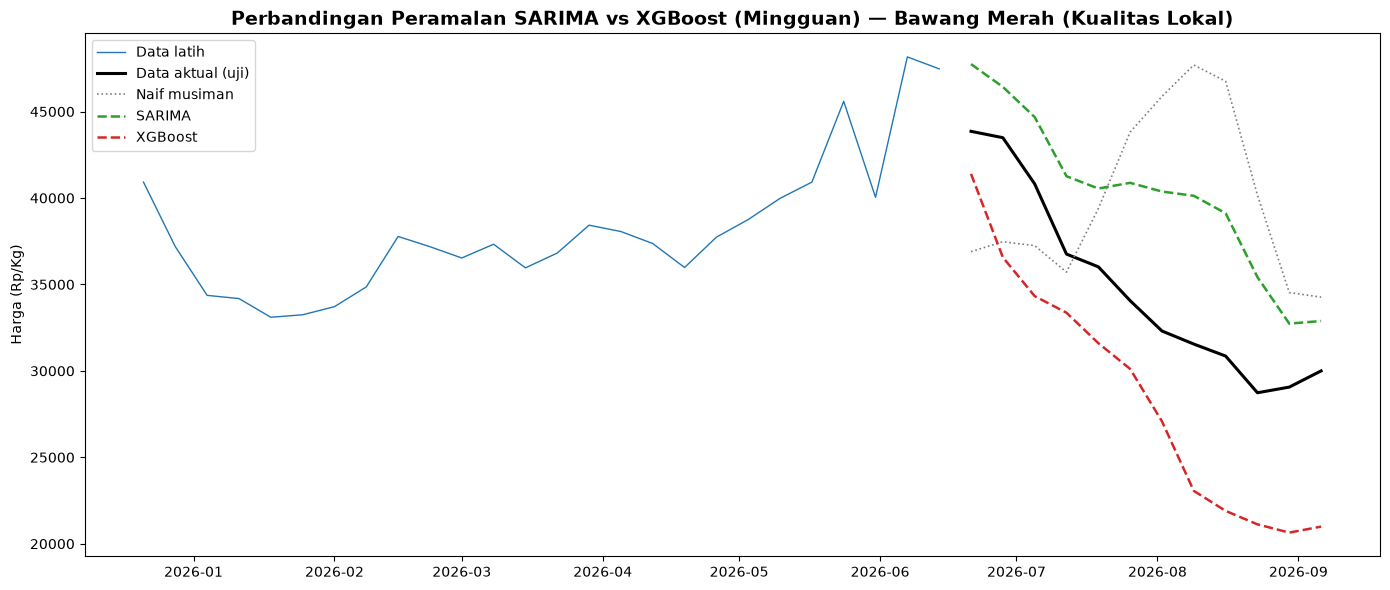

In [11]:
# Visualisasi perbandingan hasil peramalan
plt.figure(figsize=(14, 6))

# 26 minggu terakhir data latih sebagai konteks
plt.plot(train.iloc[-26:], color="tab:blue", lw=1, label="Data latih")
plt.plot(test, color="black", lw=2.2, label="Data aktual (uji)")
plt.plot(pred_naive, color="tab:gray", lw=1.2, ls=":",
         label="Naif musiman")
plt.plot(pred_sarima, color="tab:green", lw=1.8, ls="--",
         label="SARIMA")
plt.plot(pred_xgb, color="tab:red", lw=1.8, ls="--",
         label="XGBoost")

plt.title(f"Perbandingan Peramalan SARIMA vs XGBoost (Mingguan) — {KOMODITAS}",
          fontsize=14, fontweight="bold")
plt.ylabel("Harga (Rp/Kg)")
plt.legend()
plt.tight_layout()
plt.savefig("perbandingan_sarima_xgboost.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Interpretasi Hasil

Perbandingan didasarkan pada nilai MAE, RMSE, dan MASE pada tabel di atas. Model dengan ketiga nilai terendah dinyatakan lebih akurat dalam meramalkan harga mingguan Bawang Merah di Kota Surabaya. Nilai **MASE** menegaskan apakah model benar-benar lebih baik daripada tolok ukur naif musiman (MASE < 1).

Hal yang dapat dibahas pada poster (bagian Hasil & Pembahasan):
- Metode mana yang menghasilkan galat lebih kecil, dan selisihnya.
- Apakah kedua model mengikuti pola musiman data uji.
- Pada minggu keberapa galat terbesar terjadi.
- Apakah model yang lebih kompleks (XGBoost) memberi keuntungan nyata dibanding SARIMA pada data ini.

 Berdasarkan evaluasi pada 12 minggu data uji, metode **(SARIMA / XGBoost)** menghasilkan MAE sebesar **Rp5390.73**, RMSE **Rp5768.74**, dan MASE **0.76**, lebih rendah daripada metode pembanding, sehingga lebih sesuai untuk meramalkan harga Bawang Merah di Kota Surabaya. Hasil ini berlaku untuk satu deret dan satu periode uji, sehingga belum tentu berlaku umum.